# R4 Bus Delays at UBC: Step-by-Step Analysis

**Question:** How reliable is the TransLink R4 when it departs UBC Exchange (Bay 4)?

**Data:** Live GTFS-Realtime updates collected every 60 seconds by a script running on Railway, saved as `r4_ubc_live_log.csv`.

Run the cells in order with **Shift+Enter**. Put the CSV in the same folder as this notebook.

## Step 1: Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("r4_ubc_live_log.csv")
print(df.shape)
df.head()

(9536, 7)


,collected_at,trip_id,route_id,stop_id,direction,arrival_delay_sec,departure_delay_sec
0,2026-09-18T17:06:47.311740+00:00,15509049,37810,12361,departing_UBC,0.0,0.0
1,2026-09-18T17:07:48.021986+00:00,15509049,37810,12361,departing_UBC,0.0,0.0
2,2026-09-18T17:20:57.540774+00:00,15509051,37810,12361,departing_UBC,0.0,0.0
3,2026-09-18T17:21:58.234228+00:00,15509051,37810,12361,departing_UBC,0.0,0.0
4,2026-09-18T18:08:33.328110+00:00,15509055,37810,12361,departing_UBC,1210.0,1210.0


Each row is **one poll of the live feed**, not one bus. A bus sitting near the stop gets logged every minute until it leaves.

## Step 2: Check data quality before analyzing

In [2]:
df["collected_at"] = pd.to_datetime(df["collected_at"], utc=True)

print("Date range:", df["collected_at"].min(), "to", df["collected_at"].max())
print()
print("Rows per direction:")
print(df["direction"].value_counts())
print()
print("Rows with a blank delay value:", df["arrival_delay_sec"].isna().sum(), "of", len(df))
print("Duplicate rows:", df.duplicated().sum())

Date range: 2026-09-18 17:06:47.311740+00:00 to 2026-10-26 22:15:23.105314+00:00

Rows per direction:
direction
departing_UBC    9536
Name: count, dtype: int64

Rows with a blank delay value: 4499 of 9536
Duplicate rows: 0


Two things to note:
- Only `departing_UBC` appears. The arriving stop (Unloading Only) is in the *schedule* but TransLink's live feed never reports it, so this analysis covers **departures only**.
- Many rows have a blank delay. The feed knew a trip existed but had not attached timing yet. Those rows carry no delay information, so we drop them.

## Step 3: Clean the data

The timestamps are in UTC. Convert to Vancouver time so that "hour" and "weekday" match what riders experience.

In [3]:
df = df.dropna(subset=["arrival_delay_sec"]).copy()
df["arrival_delay_sec"] = df["arrival_delay_sec"].astype(int)
df["delay_min"] = df["arrival_delay_sec"] / 60
df["collected_at"] = df["collected_at"].dt.tz_convert("America/Vancouver")

print(len(df), "rows with delay data")
df.head()

5037 rows with delay data


,collected_at,trip_id,route_id,stop_id,direction,arrival_delay_sec,departure_delay_sec,delay_min
0,2026-09-18 10:06:47.311740-07:00,15509049,37810,12361,departing_UBC,0,0.0,0.000000
1,2026-09-18 10:07:48.021986-07:00,15509049,37810,12361,departing_UBC,0,0.0,0.000000
2,2026-09-18 10:20:57.540774-07:00,15509051,37810,12361,departing_UBC,0,0.0,0.000000
3,2026-09-18 10:21:58.234228-07:00,15509051,37810,12361,departing_UBC,0,0.0,0.000000
4,2026-09-18 11:08:33.328110-07:00,15509055,37810,12361,departing_UBC,1210,1210.0,20.166667


## Step 4: One row per bus run

`trip_id` is a *scheduled* trip, and the **same trip_id runs every day**. So we can't group by `trip_id` alone or different days get merged together. Instead, a new "run" starts whenever a trip_id reappears after a gap of more than 3 hours.

For each run we keep its **last** delay reading: it is closest to the actual departure, and early predictions in this feed are sometimes off by 10-30 minutes before correcting themselves.

In [4]:
df = df.sort_values(["trip_id", "collected_at"])
gap = df.groupby("trip_id")["collected_at"].diff()
new_run = gap.isna() | (gap > pd.Timedelta(hours=3))
df["run_id"] = new_run.cumsum()

runs = df.sort_values("collected_at").groupby("run_id").last().reset_index()
runs["hour"] = runs["collected_at"].dt.hour
runs["weekday"] = runs["collected_at"].dt.day_name()

print(len(df), "polls collapsed into", len(runs), "bus runs")

5037 polls collapsed into 1681 bus runs


## Step 5: Overall reliability

We call a bus **on time** if it is within 5 minutes of schedule. That threshold is a common transit convention, and you can change it below.

In [5]:
ON_TIME_MIN = 5
runs["on_time"] = runs["delay_min"].abs() <= ON_TIME_MIN

print("Bus runs tracked:", len(runs))
print("Median delay (min):", round(runs["delay_min"].median(), 1))
print("Mean delay (min):  ", round(runs["delay_min"].mean(), 1))
print(f"On-time rate (within {ON_TIME_MIN} min): {runs['on_time'].mean() * 100:.1f}%")
print("Runs more than 10 min late:", (runs["delay_min"] > 10).sum())

Bus runs tracked: 1681
Median delay (min): 0.0
Mean delay (min):   0.5
On-time rate (within 5 min): 97.9%
Runs more than 10 min late: 13


## Step 6: What does the delay distribution look like?

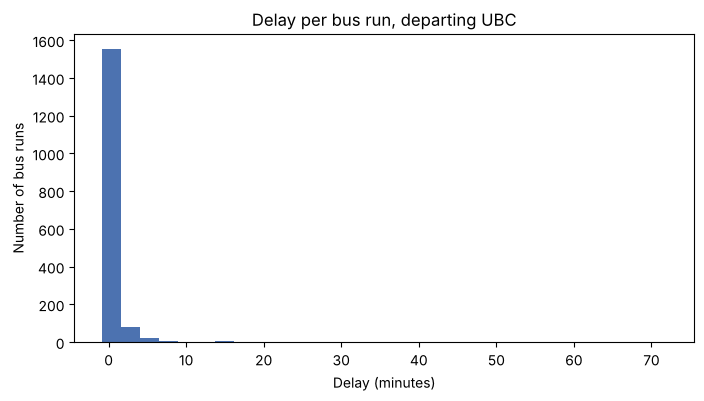

In [6]:
plt.figure(figsize=(8, 4))
plt.hist(runs["delay_min"], bins=30, color="#4C72B0")
plt.title("Delay per bus run, departing UBC")
plt.xlabel("Delay (minutes)")
plt.ylabel("Number of bus runs")
plt.show()

Most buses cluster at zero, with a long thin tail of late buses.

## Step 7: Delay by hour of day (Vancouver time)

,mean,median,count
hour,,,
0,1.7,1.0,124
1,1.2,0.4,30
5,0.3,0.2,82
6,0.9,0.4,179
7,0.1,0.0,64
8,0.2,0.0,78
9,1.8,0.0,43
10,0.2,0.0,73
11,0.5,0.0,48


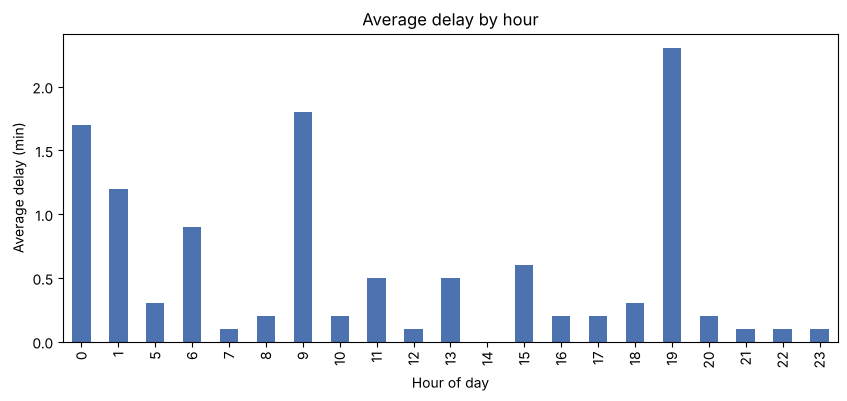

In [7]:
by_hour = runs.groupby("hour")["delay_min"].agg(["mean", "median", "count"]).round(1)
display(by_hour)

by_hour["mean"].plot(kind="bar", figsize=(10, 4), color="#4C72B0")
plt.title("Average delay by hour")
plt.xlabel("Hour of day")
plt.ylabel("Average delay (min)")
plt.show()

Check the `count` column before trusting a tall bar. An hour with 16 runs can be swung by two very late buses.

## Step 8: Delay by weekday

,mean_delay,on_time_rate,runs
weekday,,,
Monday,0.55,0.99,292
Tuesday,0.39,0.99,270
Wednesday,0.57,0.97,260
Thursday,0.41,0.98,253
Friday,0.49,0.98,289
Saturday,0.56,0.98,164
Sunday,0.90,0.94,153


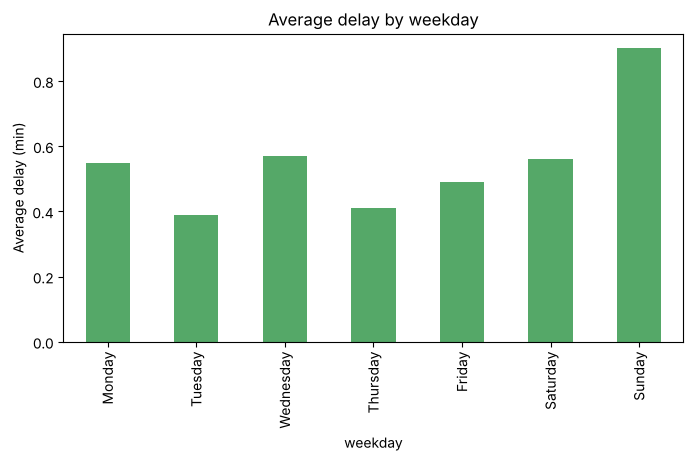

In [8]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = runs.groupby("weekday").agg(
    mean_delay=("delay_min", "mean"),
    on_time_rate=("on_time", "mean"),
    runs=("delay_min", "count"),
).reindex(order).round(2)
display(by_day)

by_day["mean_delay"].plot(kind="bar", figsize=(8, 4), color="#55A868")
plt.title("Average delay by weekday")
plt.ylabel("Average delay (min)")
plt.show()

## Step 9: The biggest delays

Look at extreme values individually, to judge whether they are real delays or feed glitches.

In [9]:
runs.sort_values("delay_min", ascending=False)[["collected_at", "trip_id", "delay_min"]].head(10)

,collected_at,trip_id,delay_min
1254,2026-10-19 09:04:32.482762-07:00,15509210,71.883333
102,2026-09-18 11:09:34.066617-07:00,15509055,20.166667
1397,2026-10-10 15:28:01.747330-07:00,15509475,19.466667
803,2026-09-24 19:34:34.850389-07:00,15509158,15.883333
1555,2026-09-20 15:21:02.503627-07:00,15509699,15.633333
807,2026-10-13 19:38:14.115076-07:00,15509159,15.500000
810,2026-09-25 19:44:04.049457-07:00,15509160,15.100000
181,2026-09-23 13:10:56.252126-07:00,15509072,14.300000
1541,2026-09-30 13:12:24.501592-07:00,15509688,13.900000
808,2026-09-22 19:43:35.700315-07:00,15509160,13.033333


## Step 10: Predictive model: can we predict which runs will be late?

**Target.** Predicting the exact delay in minutes isn't useful here, because about 98% of runs are at or near 0. Instead I ask a yes/no question: *will this run be more than 5 minutes late?* (the same threshold as Step 5).

**Features.** Only things known before the bus leaves: hour of day, day of week, and whether it is a weekend. No feed values from the run itself are used.

**How I test it.** Runs are ordered by time. The model trains on earlier weeks and is scored on the *later* weeks it hasn't seen (`TimeSeriesSplit`). A random shuffle would leak the future into training and look better than it really is.

In [10]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, average_precision_score

m = runs.sort_values("collected_at").reset_index(drop=True).copy()
m["late"] = (m["delay_min"] > ON_TIME_MIN).astype(int)
m["weekend"] = m["collected_at"].dt.dayofweek.isin([5, 6]).astype(int)

X = pd.get_dummies(m[["hour"]].astype(str).join(m["collected_at"].dt.dayofweek.astype(str).rename("dow")))
X["weekend"] = m["weekend"]
y = m["late"]

print("Runs:", len(m), "| late (>5 min):", y.sum(), f"({y.mean():.1%})")
print("A model that always says 'on time' is right", f"{1 - y.mean():.1%}", "of the time, so accuracy is a useless score here.")

Runs: 1681 | late (>5 min): 35 (2.1%)
A model that always says 'on time' is right 97.9% of the time, so accuracy is a useless score here.


In [11]:
def time_cv(make_model, X, y, n_splits=4):
    rows = []
    for fold, (tr, te) in enumerate(TimeSeriesSplit(n_splits).split(X), 1):
        if y.iloc[te].sum() == 0 or y.iloc[tr].sum() == 0:
            continue
        p = make_model().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        rows.append({"fold": fold, "test_runs": len(te), "late_in_test": int(y.iloc[te].sum()),
                     "base_rate": y.iloc[te].mean(),
                     "ROC_AUC": roc_auc_score(y.iloc[te], p),
                     "avg_precision": average_precision_score(y.iloc[te], p)})
    return pd.DataFrame(rows).set_index("fold")

models = {
    "Logistic regression": lambda: LogisticRegression(max_iter=2000, C=0.3, class_weight="balanced"),
    "Random forest": lambda: RandomForestClassifier(300, min_samples_leaf=10, class_weight="balanced", random_state=0),
}
results = {}
for name, mk in models.items():
    res = time_cv(mk, X, y)
    results[name] = res
    print(name); display(res.round(3))
    print(f"  mean ROC-AUC {res.ROC_AUC.mean():.2f} (0.50 = coin flip) | mean avg precision {res.avg_precision.mean():.3f} vs base rate {res.base_rate.mean():.3f}\n")

Logistic regression


,test_runs,late_in_test,base_rate,ROC_AUC,avg_precision
fold,,,,,
1,336,11,0.033,0.732,0.091
2,336,4,0.012,0.954,0.131
3,336,4,0.012,0.720,0.032
4,336,9,0.027,0.691,0.128


  mean ROC-AUC 0.77 (0.50 = coin flip) | mean avg precision 0.095 vs base rate 0.021



Random forest


,test_runs,late_in_test,base_rate,ROC_AUC,avg_precision
fold,,,,,
1,336,11,0.033,0.570,0.060
2,336,4,0.012,0.967,0.177
3,336,4,0.012,0.757,0.039
4,336,9,0.027,0.673,0.081


  mean ROC-AUC 0.74 (0.50 = coin flip) | mean avg precision 0.089 vs base rate 0.021



**How to read this.** ROC-AUC of 0.5 means no better than guessing; 1.0 is perfect. *Average precision* should be compared with the base rate (the share of late runs in that test period): a model with no skill scores about the base rate.

In [12]:
# Sanity check: could a score like this happen by luck with only ~26 late runs?
# Shuffle the late/on-time labels, re-run the same time-ordered test, repeat.
rng = np.random.default_rng(0)
real = results["Logistic regression"].ROC_AUC.mean()
fake = []
for _ in range(200):
    ys = pd.Series(rng.permutation(y.values), index=y.index)
    r = time_cv(models["Logistic regression"], X, ys)
    if len(r): fake.append(r.ROC_AUC.mean())
fake = np.array(fake)
print(f"Real mean ROC-AUC: {real:.2f}")
print(f"Shuffled-label mean ROC-AUC: {fake.mean():.2f} (95th percentile {np.percentile(fake, 95):.2f})")
print(f"Share of shuffled runs that scored as high as the real model: {(fake >= real).mean():.1%}")

Real mean ROC-AUC: 0.77
Shuffled-label mean ROC-AUC: 0.49 (95th percentile 0.60)
Share of shuffled runs that scored as high as the real model: 0.0%


,hour,model_late_prob,actual_late_rate,runs
16,19,0.230,0.188,48
0,0,0.101,0.073,124
12,15,0.060,0.042,119
10,13,0.054,0.038,78
1,1,0.044,0.033,30
6,9,0.031,0.023,43


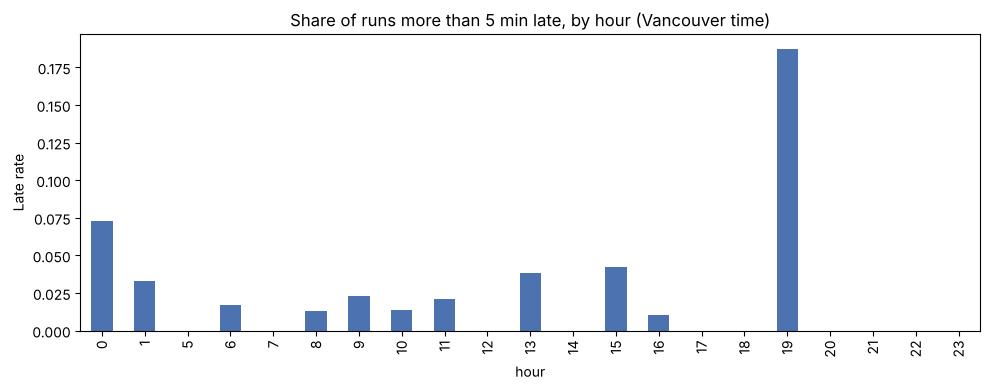

In [13]:
# Which hours does the model consider riskiest? (fit on all data; for explanation only, not a score)
# no class_weight here, and lighter regularization, so the probabilities stay close to the observed rates
final = LogisticRegression(max_iter=2000, C=10).fit(X, y)
risk = pd.DataFrame({"hour": sorted(m["hour"].unique())})
base = pd.DataFrame(0, index=risk.index, columns=X.columns)
for i, h in enumerate(risk["hour"]):
    base.loc[i, f"hour_{h}"] = 1
risk["model_late_prob"] = final.predict_proba(base)[:, 1]
risk = risk.merge(m.groupby("hour")["late"].agg(actual_late_rate="mean", runs="count").reset_index(), on="hour")
display(risk.round(3).sort_values("actual_late_rate", ascending=False).head(6))

ax = risk.set_index("hour")["actual_late_rate"].plot(kind="bar", figsize=(10, 4), color="#4C72B0")
ax.set_title("Share of runs more than 5 min late, by hour (Vancouver time)")
ax.set_ylabel("Late rate"); plt.tight_layout(); plt.show()

**Reading the model honestly.** The signal comes almost entirely from time of day: a few hours (around midnight and 7pm) have far more late runs than the rest. The model has to be wrong most of the time even at its best, because late runs are rare (about 2% of runs) and a time-of-day feature can only tell us which hours are *riskier*, not which specific bus will be late. Treat it as a ranking of risky hours, not a forecast you would act on for a single trip. More weeks of data, plus features such as weather or live traffic, would be needed for anything stronger.

## Conclusions and limitations

**Conclusions**

Over the data collected (Sep 18 to Oct 26, 2026; 33 distinct days with readings), the R4 was reliable departing UBC Exchange (Bay 4): 97.9% of the 1,681 tracked runs left within 5 minutes of schedule, and the median delay was 0 minutes. 13 runs were more than 10 minutes late. The largest value, 71.9 minutes on Oct 19 around 9:04am, is a single run whose delay stayed frozen at the same number for 8 consecutive polls before the trip disappeared from the feed. I can't tell from this data whether that was a real disruption or a feed glitch, so I kept it in the results. Without it, 1,680 runs, 97.98% on time and the worst delay is about 20 minutes.

Sunday had the lowest on-time rate of any day (94.1%, 0.9 min average delay), while Monday had the highest (99.3%). The data doesn't say why, so I'm reporting the number without assuming a cause. 7pm showed the worst hourly on-time rate (about 81%) but that is based on 48 runs and 9 late buses, and midnight was next (92.7% over 124 runs), so I'd treat these as hours to watch rather than firm patterns. Runs before Sep 29 had a 97.1% on-time rate and runs from Sep 29 on 98.3%, so the early result held up as more data arrived.

**Predictive model.** I trained logistic regression and random forest models to predict whether a run would be more than 5 minutes late, using only hour of day, weekday and weekend. Tested on later weeks the models had not seen, both ranked late runs above chance (mean ROC-AUC about 0.77 for logistic regression and 0.74 for random forest; shuffling the labels gives about 0.49), and about 4 times better than the base rate on average precision (about 0.09 vs 0.021). The signal comes almost entirely from time of day, mainly 7pm and the midnight hour. Even so, the models are far from precise: only 35 runs were late, so each test period holds just 4 to 11 late runs and the fold-to-fold results vary a lot (ROC-AUC from 0.57 to 0.97). The 71.9-minute run counts as one of the late runs. It is a ranking of riskier hours, not a reliable forecast for any single bus.

**Limitations**

- **Partial coverage:** the feed didn't return a delay reading for every scheduled trip, so this covers roughly 51 runs a day on average, not every bus. Full days range from 20 to 89 runs; Oct 26 is a partial day with 5.
- **Collection gap:** no data was collected Oct 20 to Oct 25 because the collector was offline, and it restarted only briefly on Oct 26.
- **One direction only:** the arrival stop (Unloading Only, stop 12600) never appeared in the live feed, so nothing here says anything about buses arriving at UBC.
- **Small per-hour samples:** most hours have 25 to 140 runs behind them, enough for the broad on-time rate, not enough to trust any single hour.
- **Uneven collection:** the number of runs captured varies a lot from day to day, and some weekdays were observed on only 5 days, so day-of-week comparisons are rough.
- **Delays are predictions:** the delay is the feed's last predicted delay for each run, not a measured actual departure time.
- **Few late runs for modeling:** only 35 runs were more than 5 minutes late, so the model results are early and noisy.
- **Data collected:** Sep 18 to Oct 26, 2026. Re-download the CSV and rerun the notebook to update everything.
